# Minsk Rental Market Analysis

Analysis of long-term apartment rental listings in Minsk based on a fresh market snapshot collected from Realt.by.

The project explores rental prices, location effects, apartment characteristics, seller type, and recorded price changes.

## 1. Data Loading and Preparation

The analysis uses two datasets:

- `listings_2026-09-05.csv` — current rental listings with apartment characteristics, location, prices, and seller information;
- `price_history_2026-09-05.csv` — recorded price history for the collected listings.

The datasets were collected on September 5, 2026 using the custom Realt.by collector included in this repository.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("data")

listings = pd.read_csv(DATA_DIR / "listings_2026-09-05.csv")
price_history = pd.read_csv(DATA_DIR / "price_history_2026-09-05.csv")

print("Listings shape:", listings.shape)
print("Price history shape:", price_history.shape)

Listings shape: (1551, 31)
Price history shape: (3718, 7)


### Initial Inspection

Before analysis, the datasets are checked for structure, data types, missing values, and duplicate records.

In [2]:
print("Listings:")
display(listings.head())

print("\nPrice history:")
display(price_history.head())

Listings:


,ad_code,ad_uuid,collected_at,listed_price,listed_currency,price_byn,price_usd,price_change_date,price_change_direction,rooms,...,metro_station,metro_time_min,metro_time_mode,district,subdistrict,created_at,updated_at,raise_date,new_again_date,seller_type
0,4222733,69db56c0-a69b-11f1-81ac-5b2d3dd78691,2026-09-05T14:52:45.264077+03:00,2500,USD,7698,2500,NaN,NaN,3,...,Грушевка,NaN,NaN,Московский район,"Дзержинского, Хмелевского, Щорса",2026-09-02T09:56:25+03:00,2026-09-02T10:29:55+03:00,2026-09-05T09:58:49+03:00,2026-09-02T09:56:25+03:00,private
1,4219225,8c6e0d80-a2e1-11f1-a95a-63402701d4c9,2026-09-05T14:52:45.264077+03:00,1500,USD,4619,1500,NaN,NaN,3,...,NaN,NaN,NaN,Центральный район,Лебяжий (Ржавец),2026-08-28T16:08:23+03:00,2026-09-03T13:10:54+03:00,2026-09-05T13:10:54+03:00,2026-08-28T16:08:23+03:00,private
2,4215017,957a5720-9f96-11f1-a8f3-b295db31e5cb,2026-09-05T14:52:45.264077+03:00,3571,BYN,3571,1160,NaN,NaN,3,...,Московская,NaN,NaN,Советский район,"Я.Коласа-Рига, Некрасова, Восточная",2026-08-24T11:34:12+03:00,2026-09-03T13:32:37+03:00,2026-09-05T13:32:37+03:00,2026-08-24T11:34:12+03:00,agency
3,3894259,9f290d00-9926-11f0-b3f2-a51b6a4b50f1,2026-09-05T14:52:45.264077+03:00,830,USD,2556,830,2026-09-03T07:37:52+03:00,down,2,...,Аэродромная (2024),NaN,NaN,Октябрьский район,Минск Мир (Minsk World),2025-09-24T12:12:40+03:00,2026-09-05T14:15:32+03:00,2026-09-05T14:15:32+03:00,2025-09-24T12:12:40+03:00,private
4,4220604,e2cb3290-a4a6-11f1-9c1a-db8dd9ac123b,2026-09-05T14:52:45.264077+03:00,1000,USD,3079,1000,NaN,NaN,2,...,Аэродромная (2024),NaN,walk,Октябрьский район,Минск Мир (Minsk World),2026-08-30T22:13:30+03:00,2026-08-31T10:58:52+03:00,2026-09-04T22:20:17+03:00,2026-08-30T22:13:30+03:00,private



Price history:


,ad_code,recorded_at,price_currency,price_listed,price_byn,price_usd,status
0,4222733,2026-09-02T09:58:49+03:00,USD,2500.0,7698.0,2500.0,0
1,4219225,2026-08-28T16:10:33+03:00,USD,1500.0,4619.0,1500.0,0
2,4215017,2026-08-24T11:34:12+03:00,BYN,3571.0,3571.0,1160.0,0
3,3894259,2026-09-03T07:37:52+03:00,USD,830.0,2556.0,830.0,-1
4,3894259,2026-07-04T12:39:33+03:00,USD,850.0,2617.0,850.0,1


In [3]:
print("Listings info:")
listings.info()

print("\nPrice history info:")
price_history.info()

Listings info:
<class 'pandas.DataFrame'>
RangeIndex: 1551 entries, 0 to 1550
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ad_code                 1551 non-null   int64  
 1   ad_uuid                 1551 non-null   str    
 2   collected_at            1551 non-null   str    
 3   listed_price            1551 non-null   int64  
 4   listed_currency         1551 non-null   str    
 5   price_byn               1551 non-null   int64  
 6   price_usd               1551 non-null   int64  
 7   price_change_date       819 non-null    str    
 8   price_change_direction  818 non-null    str    
 9   rooms                   1551 non-null   int64  
 10  area_total_m2           1550 non-null   float64
 11  area_living_m2          1530 non-null   float64
 12  area_kitchen_m2         652 non-null    float64
 13  floor                   1551 non-null   int64  
 14  floors_total            1551 non-nul

In [4]:
print("Duplicate listing IDs:", listings["ad_code"].duplicated().sum())

print(
    "Duplicate price history records:",
    price_history.duplicated(
        subset=["ad_code", "recorded_at"]
    ).sum(),
)

Duplicate listing IDs: 0
Duplicate price history records: 0


### Data Type Conversion

Timestamp columns are converted from strings to pandas datetime objects to enable time-based analysis.

In [5]:
listing_datetime_columns = [
    "collected_at",
    "price_change_date",
    "created_at",
    "updated_at",
    "raise_date",
    "new_again_date",
]

for column in listing_datetime_columns:
    listings[column] = pd.to_datetime(
        listings[column],
        errors="coerce",
        utc=True,
    )

price_history["recorded_at"] = pd.to_datetime(
    price_history["recorded_at"],
    errors="coerce",
    utc=True,
)

### Missing Value Review

Critical missing values are inspected before applying any cleaning rules.

In [6]:
print("Listings without total area:", listings["area_total_m2"].isna().sum())
print(
    "Price history records without prices:",
    price_history["price_listed"].isna().sum(),
)

Listings without total area: 1
Price history records without prices: 3


Three price history records contain no price values and cannot be used for price change analysis. These records are removed, while listings with partially missing apartment characteristics are retained whenever they remain useful for other parts of the analysis.

In [7]:
price_history = price_history.dropna(
    subset=["price_listed", "price_byn", "price_usd"]
).copy()

print("Price history shape after cleaning:", price_history.shape)

Price history shape after cleaning: (3715, 7)


### Numerical Data Validation

Key numerical fields are reviewed for implausible values and extreme observations before feature engineering and market analysis.

In [8]:
numeric_columns = [
    "price_usd",
    "rooms",
    "area_total_m2",
    "area_living_m2",
    "area_kitchen_m2",
    "floor",
    "floors_total",
    "building_year",
    "metro_time_min",
]

listings[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
price_usd,1551.0,833.343649,465.824023,97.0,560.000,700.0,950.000,5000.0
rooms,1551.0,2.124436,0.899098,1.0,1.000,2.0,3.000,5.0
area_total_m2,1550.0,63.522497,32.733447,24.1,43.000,55.0,72.525,360.0
area_living_m2,1530.0,42.870993,23.576629,5.0,29.625,38.0,50.700,330.0
area_kitchen_m2,652.0,11.225092,5.743319,3.0,8.000,10.0,12.300,56.0
floor,1551.0,7.508704,5.774897,1.0,3.000,6.0,10.000,83.0
floors_total,1551.0,13.039329,7.024134,1.0,9.000,10.0,19.000,37.0
building_year,1249.0,2004.282626,20.987046,1917.0,1995.000,2012.0,2020.000,2028.0
metro_time_min,554.0,6.711191,4.389242,1.0,3.000,5.0,10.000,20.0


### Handling Implausible Values

Clearly impossible structural values are replaced with missing values rather than removing entire listings. Unusually low rental prices are retained because they cannot be confidently identified as data errors without additional listing context.

In [9]:
snapshot_year = listings["collected_at"].dt.year.max()

invalid_floor_mask = listings["floor"] > listings["floors_total"]
invalid_year_mask = listings["building_year"] > snapshot_year

print("Invalid floor values:", invalid_floor_mask.sum())
print("Future building years:", invalid_year_mask.sum())

listings.loc[invalid_floor_mask, "floor"] = pd.NA
listings.loc[invalid_year_mask, "building_year"] = pd.NA

Invalid floor values: 1
Future building years: 1


### Feature Engineering

A derived metric is created for the analysis:

- `price_per_m2_usd` — monthly rent per square meter in USD.

In [10]:
listings["price_per_m2_usd"] = (
    listings["price_usd"] / listings["area_total_m2"]
)

In [11]:
listings["price_per_m2_usd"].describe()

count    1550.000000
mean       13.732876
std         4.805875
min         2.027778
25%        10.373509
50%        12.823630
75%        16.240000
max        44.776119
Name: price_per_m2_usd, dtype: float64

### Categorical Data Review

Selected categorical features are inspected to identify inconsistent source values before grouping and visualization.

In [12]:
categorical_columns = [
    "repair_state",
    "district",
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(listings[column].value_counts(dropna=False))


repair_state:
repair_state
euro                  932
good                  385
normal                103
NaN                    94
отличный               33
плохое состояние        3
удовлетворительный      1
Name: count, dtype: int64

district:
district
Центральный район                             312
Октябрьский район                             259
Первомайский район                            212
Фрунзенский район                             204
Московский район                              190
Советский район                               175
Ленинский район                                82
Партизанский район                             56
Заводской район                                39
NaN                                            18
Независимости, Немига, Романовская слобода      1
Запад, Красный Бор                              1
Макаенка                                        1
Брилевичи                                       1
Name: count, dtype: int64


### Categorical Normalization

A small number of categorical values are standardized for consistent analysis. Non-district values found in the district field are treated as missing because they do not represent Minsk administrative districts.

In [13]:
valid_districts = {
    "Центральный район",
    "Октябрьский район",
    "Первомайский район",
    "Фрунзенский район",
    "Московский район",
    "Советский район",
    "Ленинский район",
    "Партизанский район",
    "Заводской район",
}

listings.loc[
    ~listings["district"].isin(valid_districts)
    & listings["district"].notna(),
    "district",
] = pd.NA

district_map = {
    "Центральный район": "Central",
    "Октябрьский район": "Oktyabrsky",
    "Первомайский район": "Pervomaisky",
    "Фрунзенский район": "Frunzensky",
    "Московский район": "Moskovsky",
    "Советский район": "Sovetsky",
    "Ленинский район": "Leninsky",
    "Партизанский район": "Partizansky",
    "Заводской район": "Zavodskoy",
}

listings["district"] = listings["district"].replace(
    district_map
)

repair_state_map = {
    "отличный": "excellent",
    "плохое состояние": "poor",
    "удовлетворительный": "satisfactory",
}

listings["repair_state"] = listings["repair_state"].replace(
    repair_state_map
)

In [14]:
print("District categories:", listings["district"].nunique())
print("Missing districts:", listings["district"].isna().sum())
print(
    "Repair states:",
    sorted(listings["repair_state"].dropna().unique()),
)

District categories: 9
Missing districts: 22
Repair states: ['euro', 'excellent', 'good', 'normal', 'poor', 'satisfactory']


## 2. Market Overview

The analysis begins with a high-level view of the current Minsk long-term rental market, focusing on rental prices, apartment size, and room count.

In [15]:
market_overview = pd.Series(
    {
        "Listings": len(listings),
        "Median rent, USD": listings["price_usd"].median(),
        "Median rent per m², USD": listings["price_per_m2_usd"].median(),
        "Median apartment area, m²": listings["area_total_m2"].median(),
        "Median rooms": listings["rooms"].median(),
        "Private listings, %": (
            listings["seller_type"].eq("private").mean() * 100
        ),
    }
)

market_overview.round(1)

Listings                     1551.0
Median rent, USD              700.0
Median rent per m², USD        12.8
Median apartment area, m²      55.0
Median rooms                    2.0
Private listings, %            75.6
dtype: float64

### Rental Price Distribution

The rental market is right-skewed, with most listings concentrated in the mid-price segment and a smaller number of premium apartments extending the upper tail.

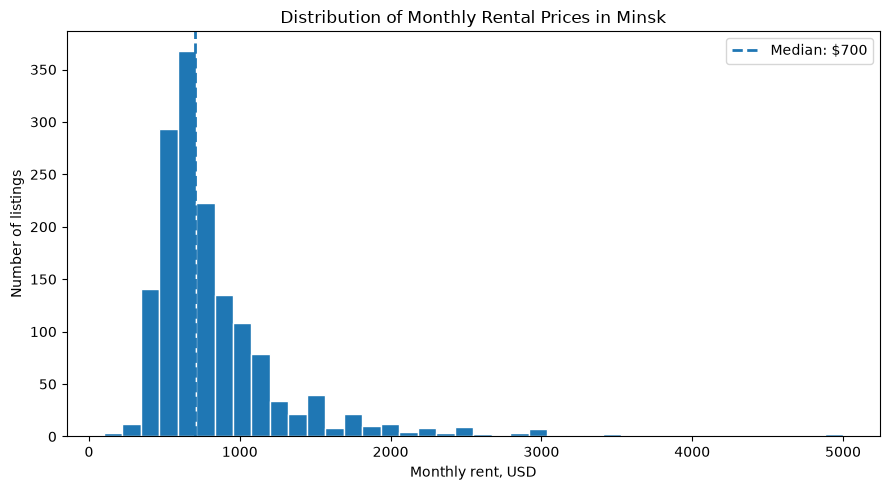

In [16]:
median_rent = listings["price_usd"].median()

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    listings["price_usd"],
    bins=40,
    edgecolor="white",
)

ax.axvline(
    median_rent,
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median_rent:,.0f}",
)

ax.set_title("Distribution of Monthly Rental Prices in Minsk")
ax.set_xlabel("Monthly rent, USD")
ax.set_ylabel("Number of listings")
ax.legend()

plt.tight_layout()
plt.show()

The median monthly rent is **$700**. The distribution is right-skewed: most listings are concentrated below the premium segment, while a relatively small number of high-priced apartments extend the upper tail.

Median values are used as the primary measure of central tendency throughout the analysis because high-priced listings would disproportionately affect the mean.

### Median Rent by Number of Rooms

Median monthly rent is compared across apartment sizes to understand how pricing changes with the number of rooms.

In [17]:
rent_by_rooms = (
    listings.groupby("rooms", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

rent_by_rooms

,rooms,listings_count,median_rent_usd,median_area_m2
0,1,414,550.0,38.0
1,2,646,700.0,53.0
2,3,387,900.0,79.9
3,4,92,1438.5,131.0
4,5,12,2211.5,195.4


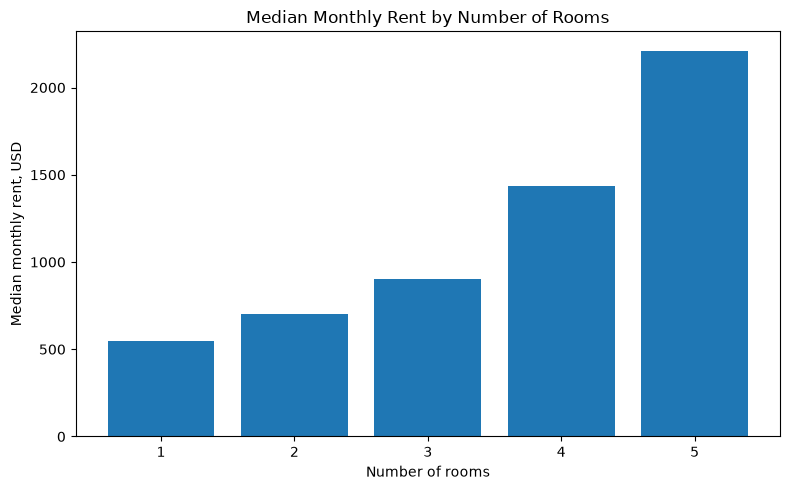

In [18]:
_, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    rent_by_rooms["rooms"].astype(str),
    rent_by_rooms["median_rent_usd"],
)

ax.set_title("Median Monthly Rent by Number of Rooms")
ax.set_xlabel("Number of rooms")
ax.set_ylabel("Median monthly rent, USD")

plt.tight_layout()
plt.show()

Rental prices increase consistently with apartment size. The median rent ranges from **$550 for one-room apartments** to more than **$2,200 for five-room apartments**.

The overall median of **$700** is not driven only by a small number of luxury listings: one- and two-room apartments already show relatively high median asking rents.

## 3. Location and Pricing

### Rental Prices by District

Rental prices are compared across Minsk administrative districts using both total monthly rent and rent per square meter.

In [19]:
district_summary = (
    listings.dropna(subset=["district"])
    .groupby("district", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
    )
    .sort_values("median_rent_usd", ascending=False)
)

district_summary

,district,listings_count,median_rent_usd,median_price_per_m2_usd
0,Central,312,942.0,13.995439
6,Pervomaisky,212,798.0,13.948231
5,Partizansky,56,700.0,12.343750
3,Moskovsky,190,687.5,12.679206
7,Sovetsky,175,682.0,11.485149
2,Leninsky,82,681.0,11.175991
4,Oktyabrsky,259,645.0,15.333333
1,Frunzensky,204,585.0,10.526316
8,Zavodskoy,39,487.0,10.847826


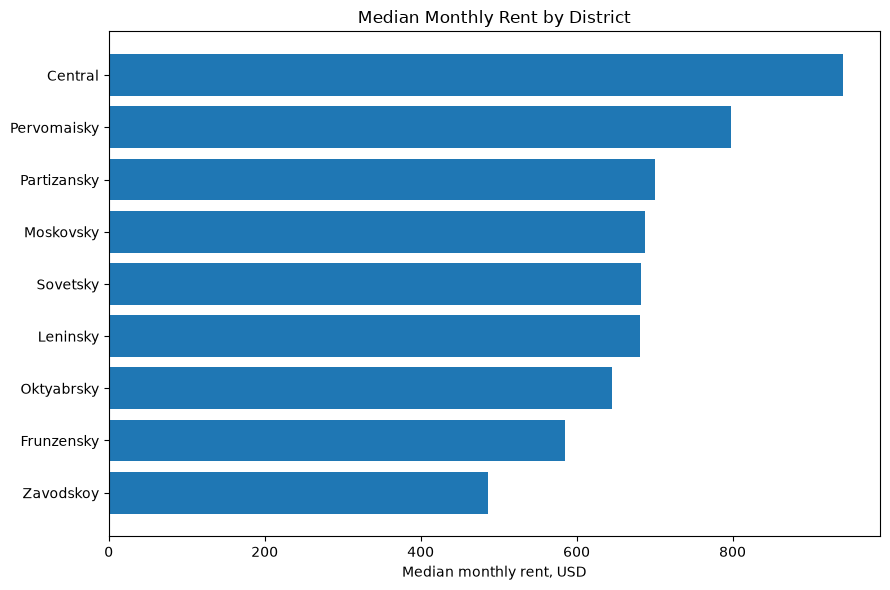

In [20]:
district_plot = district_summary.sort_values(
    "median_rent_usd",
    ascending=True,
)

_, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    district_plot["district"],
    district_plot["median_rent_usd"],
)

ax.set_title("Median Monthly Rent by District")
ax.set_xlabel("Median monthly rent, USD")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Central and Pervomaisky districts have the highest median asking rents, while Zavodskoy and Frunzensky are the most affordable.

However, total monthly rent does not fully reflect location intensity. Oktyabrsky district has a lower median monthly rent than Central or Pervomaisky, but the highest median rent per square meter, showing that total monthly rent alone does not capture district-level pricing differences.

### Rent per Square Meter by District

Rent per square meter provides a complementary view of district pricing by accounting for apartment size.

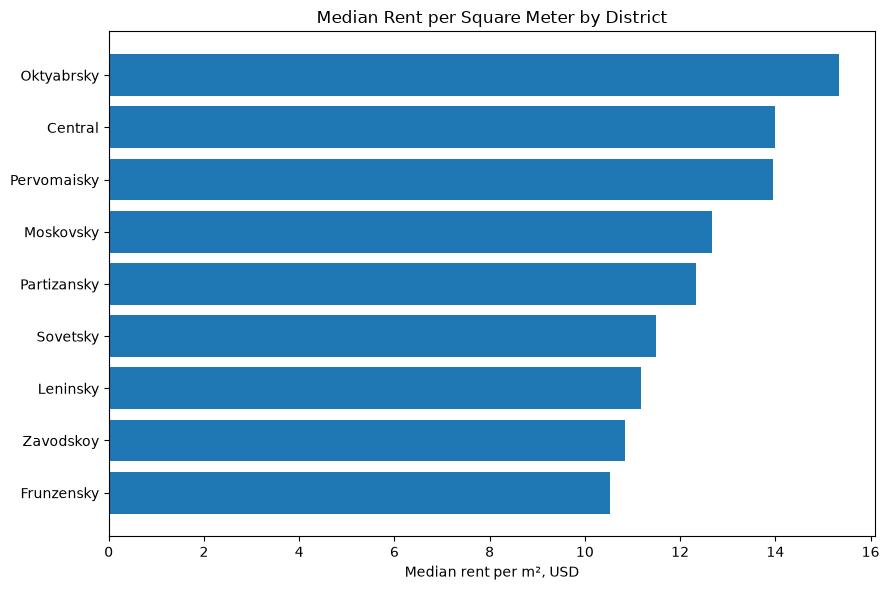

In [21]:
district_m2_plot = district_summary.sort_values(
    "median_price_per_m2_usd",
    ascending=True,
)

_, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    district_m2_plot["district"],
    district_m2_plot["median_price_per_m2_usd"],
)

ax.set_title("Median Rent per Square Meter by District")
ax.set_xlabel("Median rent per m², USD")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Oktyabrsky district has the highest median rent per square meter at approximately **$15.3/m²**, despite ranking below Central and Pervomaisky districts in total monthly rent.

This indicates that district-level affordability depends not only on total rent but also on apartment size and housing composition. Central and Pervomaisky remain expensive overall, while Oktyabrsky stands out for relatively high spatial pricing.

### Metro Accessibility

Listings are compared by the reported mode of access to the nearest metro station to assess whether better metro accessibility is associated with higher asking rents.

In [22]:
metro_summary = (
    listings.assign(
        metro_access=listings["metro_time_mode"].fillna("not specified")
    )
    .groupby("metro_access", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
    )
    .sort_values("median_rent_usd", ascending=False)
)

metro_summary

,metro_access,listings_count,median_rent_usd,median_price_per_m2_usd
0,not specified,1148,700.0,12.500000
2,walk,367,700.0,14.224138
1,transport,36,534.5,10.577467


Listings with reported walking access to the metro have the highest median rent per square meter at approximately **$14.2/m²**.

However, the `not specified` category contains most listings and should not be interpreted as poor metro accessibility. The `transport` group is also small, so differences between access categories should be interpreted cautiously.

## 4. Listing Characteristics

### Rental Prices by Repair State

Median rent and rent per square meter are compared across reported apartment repair conditions.

In [23]:
repair_summary = (
    listings.dropna(subset=["repair_state"])
    .groupby("repair_state", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
    )
    .sort_values("median_rent_usd", ascending=False)
)

repair_summary

,repair_state,listings_count,median_rent_usd,median_price_per_m2_usd
1,excellent,33,1259.0,15.759209
0,euro,932,780.0,13.976744
2,good,385,600.0,11.288136
5,satisfactory,1,600.0,6.857143
3,normal,103,494.0,10.156250
4,poor,3,487.0,6.081081


Better reported repair condition is associated with higher median asking rents, although the smallest condition categories contain too few listings for reliable comparison.

### Furnished vs Unfurnished Listings

Median asking rents are compared between furnished and unfurnished apartments.

In [24]:
furniture_summary = (
    listings.groupby("has_furniture", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

furniture_summary

,has_furniture,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,False,117,700.0,12.633333,60.0
1,True,1434,700.0,12.854077,55.0


Furnished and unfurnished listings have nearly identical median asking rents and rent per square meter. In this snapshot, furniture availability does not appear to be a major pricing factor.

### Agency vs Private Listings

Asking rents are compared between listings classified as agency and private based on the presence of explicit agency metadata.

In [25]:
seller_summary = (
    listings.groupby("seller_type", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

seller_summary

,seller_type,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,agency,378,812.0,13.069113,65.2
1,private,1173,653.0,12.765957,51.3


Agency listings have a higher median monthly asking rent than private listings, but they also represent larger apartments on average. Median rent per square meter is nearly identical between the two groups, suggesting that the difference in total rent is primarily associated with apartment size rather than seller type itself.

Listings with explicit agency metadata were classified as agency listings; all remaining listings were treated as private listings.

## 5. Recorded Price Changes

The source provides recorded price history for a subset of listings. These records are used to examine how often asking prices were changed and whether increases or decreases were more common.

A `status` value of `0` represents a baseline record in the available source history, while `1` and `-1` indicate recorded price increases and decreases.

In [26]:
price_change_summary = (
    price_history["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="records")
    .sort_values("status")
)

price_change_summary

,status,records
1,-1,1184
0,0,1511
2,1,1020


In [27]:
listing_change_summary = (
    price_history.groupby("ad_code")
    .agg(
        history_records=("recorded_at", "count"),
        increases=("status", lambda x: (x == 1).sum()),
        decreases=("status", lambda x: (x == -1).sum()),
    )
)

listings_with_history = listing_change_summary.shape[0]
listings_with_changes = (
    (listing_change_summary["increases"] > 0)
    | (listing_change_summary["decreases"] > 0)
).sum()

print("Listings with recorded price history:", listings_with_history)
print("Listings with at least one recorded price change:", listings_with_changes)
print(f"Share with recorded changes: {listings_with_changes / listings_with_history:.1%}")

Listings with recorded price history: 1504
Listings with at least one recorded price change: 760
Share with recorded changes: 50.5%


Recorded price changes are available for a substantial part of the market: **760 listings (50.5% of listings with available price history)** contain at least one recorded increase or decrease.

Across all recorded change events, price decreases are somewhat more common than increases. However, individual listings may contain multiple price changes, so event counts alone do not show how many apartments experienced each type of adjustment.

In [28]:
def classify_price_changes(row):
    if row["increases"] > 0 and row["decreases"] > 0:
        return "both"
    if row["increases"] > 0:
        return "increase only"
    if row["decreases"] > 0:
        return "decrease only"
    return "no recorded change"


listing_change_summary["change_type"] = (
    listing_change_summary.apply(classify_price_changes, axis=1)
)

change_type_summary = (
    listing_change_summary["change_type"]
    .value_counts()
    .rename_axis("change_type")
    .reset_index(name="listings")
)

change_type_summary

,change_type,listings
0,no recorded change,744
1,both,315
2,decrease only,246
3,increase only,199


Among listings with recorded price changes, the most common pattern is a combination of both increases and decreases. Listings that experienced at least one decrease are also somewhat more common than listings that experienced at least one increase, suggesting that asking prices are actively adjusted in both directions rather than following a simple one-way pattern.

In [29]:
price_history_sorted = price_history.sort_values(
    ["ad_code", "recorded_at"]
).copy()

price_history_sorted["previous_price"] = (
    price_history_sorted.groupby("ad_code")["price_listed"].shift()
)

price_history_sorted["previous_currency"] = (
    price_history_sorted.groupby("ad_code")["price_currency"].shift()
)

same_currency_changes = price_history_sorted.loc[
    (price_history_sorted["status"] != 0)
    & (
        price_history_sorted["price_currency"]
        == price_history_sorted["previous_currency"]
    )
].copy()

same_currency_changes["change_pct"] = (
    (
        same_currency_changes["price_listed"]
        - same_currency_changes["previous_price"]
    )
    / same_currency_changes["previous_price"]
    * 100
)

In [30]:
change_direction_summary = (
    same_currency_changes.assign(
        direction=same_currency_changes["status"].map(
            {-1: "decrease", 1: "increase"}
        )
    )
    .groupby("direction")["change_pct"]
    .agg(
        records="count",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
    )
)

change_direction_summary.round(1)

,records,median,q1,q3
direction,,,,
decrease,1081,-7.1,-11.1,-3.9
increase,887,11.1,5.3,21.3


Recorded price increases tend to be larger than decreases. The median increase is approximately **11.1%**, compared with a median decrease of **7.1%** in absolute terms.

Median and quartile statistics are used instead of the mean because the source history contains several extreme price adjustments that would strongly distort average percentage changes.

### Frequency of Price Adjustments

The number of recorded price changes per listing is examined to understand whether asking prices are typically adjusted once or revised multiple times.

In [31]:
listing_change_summary["change_events"] = (
    listing_change_summary["increases"]
    + listing_change_summary["decreases"]
)

change_events = listing_change_summary.loc[
    listing_change_summary["change_events"] > 0,
    "change_events",
]

price_adjustment_frequency = pd.Series(
    {
        "Listings with price changes": len(change_events),
        "Median changes per listing": change_events.median(),
        "Changed once, %": (change_events == 1).mean() * 100,
        "Changed multiple times, %": (change_events >= 2).mean() * 100,
        "Maximum recorded changes": change_events.max(),
    }
)

price_adjustment_frequency.round(1)

Listings with price changes    760.0
Median changes per listing       2.0
Changed once, %                 43.4
Changed multiple times, %       56.6
Maximum recorded changes        55.0
dtype: float64

Price adjustments are often not one-time events. More than half of the listings with recorded price changes were revised multiple times, with a median of two changes per listing. A small number of listings show substantially more frequent repricing.

### Price Adjustments by Market Segment

Listings are divided into three equally sized price segments based on their current asking rent to examine whether repricing activity differs across the market.

In [32]:
listings["price_segment"] = pd.qcut(
    listings["price_usd"],
    q=3,
    labels=["lower", "middle", "higher"],
)

change_by_listing = (
    listing_change_summary
    .reset_index()
    .assign(
        has_price_change=lambda df: df["change_events"] > 0
    )
)

segment_changes = (
    listings[
        ["ad_code", "price_usd", "price_segment"]
    ]
    .merge(
        change_by_listing[
            ["ad_code", "has_price_change"]
        ],
        on="ad_code",
        how="inner",
    )
    .groupby(
        "price_segment",
        observed=True,
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        listings_with_changes=("has_price_change", "sum"),
        share_with_changes=("has_price_change", "mean"),
    )
)

segment_changes["share_with_changes"] *= 100

segment_changes.round(1)

,price_segment,listings_count,median_rent_usd,listings_with_changes,share_with_changes
0,lower,528,501.5,237,44.9
1,middle,477,700.0,268,56.2
2,higher,499,1100.0,255,51.1


Price adjustment activity is highest in the middle price segment, where **56.2%** of listings have at least one recorded price change. The lower segment shows the lowest repricing activity at **44.9%**, while the higher segment falls in between at **51.1%**.

This suggests that repricing frequency does not increase consistently with asking rent and may reflect different seller behavior across market segments.

### Direction of Price Changes by Market Segment

The share of listings with recorded price increases and decreases is compared across price segments to examine whether seller behavior differs between lower-, middle-, and higher-priced apartments.

In [33]:
segment_direction = (
    listings[
        ["ad_code", "price_segment"]
    ]
    .merge(
        listing_change_summary.reset_index()[
            ["ad_code", "increases", "decreases"]
        ],
        on="ad_code",
        how="inner",
    )
    .assign(
        had_increase=lambda df: df["increases"] > 0,
        had_decrease=lambda df: df["decreases"] > 0,
    )
    .groupby(
        "price_segment",
        observed=True,
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        share_with_increase=("had_increase", "mean"),
        share_with_decrease=("had_decrease", "mean"),
    )
)

segment_direction[
    ["share_with_increase", "share_with_decrease"]
] *= 100

segment_direction.round(1)

,price_segment,listings_count,share_with_increase,share_with_decrease
0,lower,528,32.2,32.6
1,middle,477,35.4,44.2
2,higher,499,35.1,35.7


Price increases and decreases occur at nearly equal rates in the lower and higher price segments.

The middle segment stands out: **44.2%** of listings experienced at least one recorded decrease, compared with **35.4%** that experienced an increase. This suggests stronger downward price adjustment activity in the middle of the market.

## 6. Combined Pricing Analysis

Single-factor comparisons can be influenced by differences in apartment composition across districts. To better isolate location effects, rental prices are compared within apartments of the same room count.

The analysis focuses on one-, two-, and three-room apartments, which represent the largest market segments and provide more reliable district-level comparisons.

### Rent by District and Number of Rooms

In [34]:
district_room_summary = (
    listings.dropna(subset=["district"])
    .loc[lambda df: df["rooms"].isin([1, 2, 3])]
    .groupby(
        ["district", "rooms"],
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
    .sort_values(
        ["rooms", "median_rent_usd"],
        ascending=[True, False],
    )
)

district_room_summary.round(1)

,district,rooms,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,Central,1,47,650.0,15.0,42.0
9,Moskovsky,1,55,600.0,13.2,45.0
12,Oktyabrsky,1,93,550.0,16.7,32.0
18,Pervomaisky,1,57,550.0,15.2,37.0
21,Sovetsky,1,35,550.0,13.3,42.9
3,Frunzensky,1,71,490.0,12.2,40.5
6,Leninsky,1,18,460.5,11.9,37.8
15,Partizansky,1,11,460.0,13.1,40.0
24,Zavodskoy,1,15,438.0,12.5,32.9
1,Central,2,138,877.0,14.6,60.1


In [35]:
reliable_districts = (
    district_room_summary
    .groupby("district")
    .filter(
        lambda group: (
            (group["rooms"].nunique() == 3)
            and (group["listings_count"] >= 20).all()
        )
    )
)

rent_by_district_rooms = (
    reliable_districts
    .pivot(
        index="district",
        columns="rooms",
        values="median_rent_usd",
    )
    .rename(
        columns={
            1: "1 room",
            2: "2 rooms",
            3: "3 rooms",
        }
    )
)

rent_by_district_rooms

rooms,1 room,2 rooms,3 rooms
district,,,
Central,650.0,877.0,1100.0
Frunzensky,490.0,585.0,750.0
Moskovsky,600.0,700.0,942.0
Oktyabrsky,550.0,650.0,900.0
Pervomaisky,550.0,796.0,900.0
Sovetsky,550.0,650.0,785.0


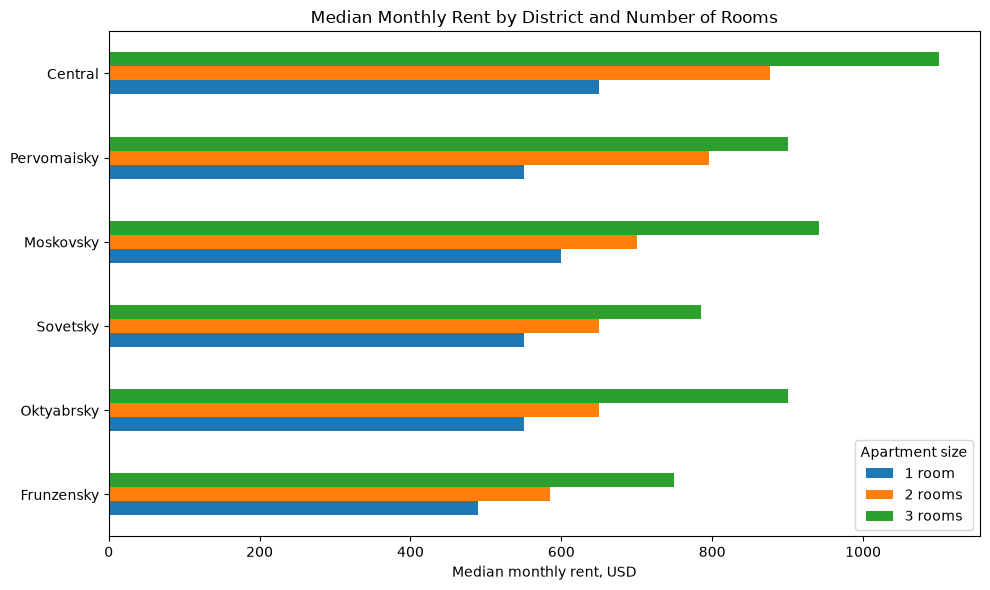

In [36]:
rent_by_district_rooms_plot = (
    rent_by_district_rooms
    .sort_values("2 rooms")
)

ax = rent_by_district_rooms_plot.plot(
    kind="barh",
    figsize=(10, 6),
)

ax.set_title("Median Monthly Rent by District and Number of Rooms")
ax.set_xlabel("Median monthly rent, USD")
ax.set_ylabel("")
ax.legend(title="Apartment size")

plt.tight_layout()
plt.show()

Location differences remain visible even when apartments are compared within the same room-count category.

Central district has the highest median asking rent for one-, two-, and three-room apartments among districts with sufficient observations. Frunzensky district remains one of the more affordable locations across all three apartment sizes.

This indicates that district-level price differences persist even when apartments are compared within the same room-count category.

### Distance to Central Minsk

To examine the location premium more directly, the straight-line distance from each listing to Independence Square is calculated using listing coordinates.

Independence Square (`53.8956, 27.5478`) is used as a reproducible reference point for central Minsk rather than as the exact geographic center of the city.

In [37]:
from math import asin, cos, radians, sin, sqrt


CENTER_LAT = 53.8956
CENTER_LON = 27.5478


def haversine_distance_km(lat, lon, center_lat=CENTER_LAT, center_lon=CENTER_LON):
    earth_radius_km = 6371.0

    lat1 = radians(lat)
    lon1 = radians(lon)
    lat2 = radians(center_lat)
    lon2 = radians(center_lon)

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        sin(delta_lat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(delta_lon / 2) ** 2
    )

    return 2 * earth_radius_km * asin(sqrt(a))


listings["distance_to_center_km"] = listings.apply(
    lambda row: haversine_distance_km(
        row["latitude"],
        row["longitude"],
    ),
    axis=1,
)

listings["distance_to_center_km"].describe()

count    1551.000000
mean        4.821822
std         2.485323
min         0.144934
25%         2.796730
50%         4.555462
75%         6.712333
max        15.353376
Name: distance_to_center_km, dtype: float64

In [38]:
listings["center_distance_zone"] = pd.cut(
    listings["distance_to_center_km"],
    bins=[0, 3, 5, 7, float("inf")],
    labels=[
        "0–3 km",
        "3–5 km",
        "5–7 km",
        "7+ km",
    ],
    right=False,
)

distance_summary = (
    listings.groupby(
        "center_distance_zone",
        observed=True,
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

distance_summary.round(1)

,center_distance_zone,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,0–3 km,455,799.0,13.9,59.0
1,3–5 km,391,650.0,13.5,50.0
2,5–7 km,361,670.0,11.9,57.0
3,7+ km,344,667.5,11.9,58.0


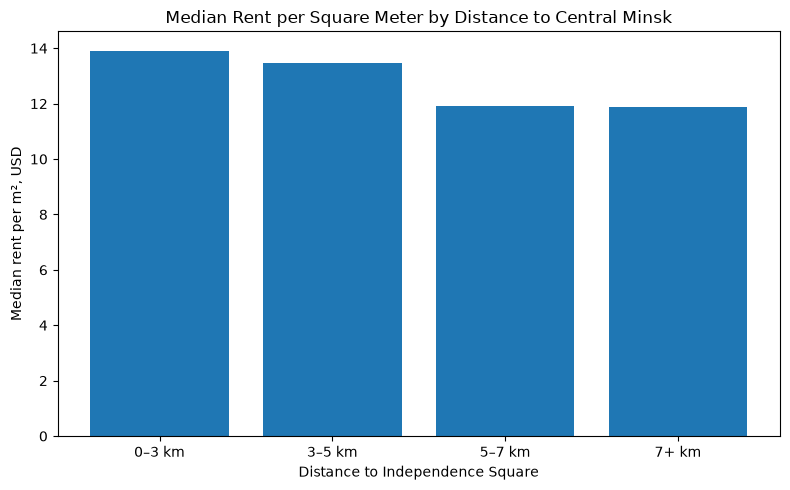

In [39]:
_, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    distance_summary["center_distance_zone"].astype(str),
    distance_summary["median_price_per_m2_usd"],
)

ax.set_title("Median Rent per Square Meter by Distance to Central Minsk")
ax.set_xlabel("Distance to Independence Square")
ax.set_ylabel("Median rent per m², USD")

plt.tight_layout()
plt.show()

Listings within **5 km of Independence Square** have higher median rent per square meter than listings located farther away.

The premium is strongest within the central 3 km, at approximately **$13.9/m²**, and remains similar at **$13.5/m²** between 3 and 5 km. Beyond 5 km, the median falls to about **$11.9/m²**.

Total monthly rent does not decline as consistently with distance because apartment sizes differ across zones, making rent per square meter a more informative measure of the location premium.

### Relationship Between Distance and Rental Price

The relationship between distance to central Minsk and rental pricing is examined across individual listings using Spearman rank correlation.

In [40]:
distance_rank = listings["distance_to_center_km"].rank()

distance_correlations = pd.Series(
    {
        "Rent, USD": distance_rank.corr(
            listings["price_usd"].rank()
        ),
        "Rent per m², USD": distance_rank.corr(
            listings["price_per_m2_usd"].rank()
        ),
    }
)

distance_correlations.round(3)

Rent, USD          -0.191
Rent per m², USD   -0.213
dtype: float64

In [41]:
distance_by_rooms = (
    listings.loc[
        listings["rooms"].isin([1, 2, 3])
    ]
    .groupby("rooms")
    .apply(
        lambda group: pd.Series(
            {
                "listings_count": len(group),
                "rent_correlation": (
                    group["distance_to_center_km"]
                    .rank()
                    .corr(group["price_usd"].rank())
                ),
                "price_per_m2_correlation": (
                    group["distance_to_center_km"]
                    .rank()
                    .corr(group["price_per_m2_usd"].rank())
                ),
            }
        ),
        include_groups=False,
    )
)

distance_by_rooms.round(3)

,listings_count,rent_correlation,price_per_m2_correlation
rooms,,,
1,414.0,-0.244,-0.319
2,646.0,-0.168,-0.182
3,387.0,-0.279,-0.261


The negative relationship between distance and rental prices remains visible within one-, two-, and three-room apartments.

The association is strongest for one-room apartments, where the Spearman correlation between distance and rent per square meter is approximately **−0.32**. Similar negative relationships are also observed for two- and three-room apartments.

This suggests that the central location premium is not driven solely by differences in room-count composition.

### Rent per Square Meter by District and Number of Rooms

Rent per square meter is compared within the same room-count categories to reduce the influence of apartment size when examining district-level pricing differences.

In [42]:
price_per_m2_by_district_rooms = (
    reliable_districts
    .pivot(
        index="district",
        columns="rooms",
        values="median_price_per_m2_usd",
    )
    .rename(
        columns={
            1: "1 room",
            2: "2 rooms",
            3: "3 rooms",
        }
    )
)

price_per_m2_by_district_rooms.round(1)

rooms,1 room,2 rooms,3 rooms
district,,,
Central,15.0,14.6,13.7
Frunzensky,12.2,10.5,9.2
Moskovsky,13.2,12.7,11.2
Oktyabrsky,16.7,14.7,13.9
Pervomaisky,15.2,14.4,11.1
Sovetsky,13.3,12.5,9.8


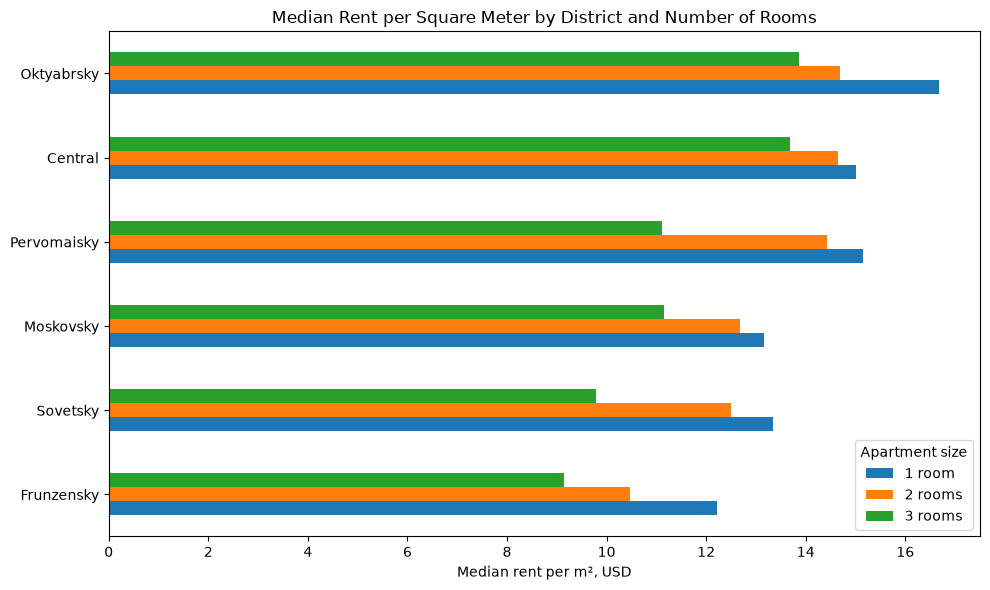

In [43]:
price_per_m2_plot = (
    price_per_m2_by_district_rooms
    .sort_values("2 rooms")
)

ax = price_per_m2_plot.plot(
    kind="barh",
    figsize=(10, 6),
)

ax.set_title(
    "Median Rent per Square Meter by District and Number of Rooms"
)
ax.set_xlabel("Median rent per m², USD")
ax.set_ylabel("")
ax.legend(title="Apartment size")

plt.tight_layout()
plt.show()

Oktyabrsky district has the highest median rent per square meter across one-, two-, and three-room apartments among districts with sufficient observations. Central district follows closely in all three categories.

Frunzensky district remains consistently more affordable, particularly for two- and three-room apartments.

These results reinforce the presence of a location premium that persists even when apartment room count is held constant.

## 7. Key Findings

* The median asking rent in the snapshot is **$700 per month**, with a median rent of approximately **$12.8/m²**. Rental prices are right-skewed, so median values provide a more representative measure than the mean.

* Location remains an important pricing factor even within comparable room-count categories. **Central district** has the highest median monthly rent across one-, two-, and three-room apartments among districts with sufficient observations, while **Oktyabrsky district** has the highest median rent per square meter across all three categories.

* A central-location premium is visible beyond administrative district boundaries. Listings within **5 km of Independence Square** have median rents of approximately **$13.5–13.9/m²**, compared with about **$11.9/m²** farther away. A modest negative relationship between distance and rental price also remains visible within one-, two-, and three-room apartments.

* Agency listings have a higher median monthly rent than private listings (**$812 vs $653**), but they also represent larger apartments. Their median rent per square meter is nearly identical, suggesting that the difference is primarily related to listing composition rather than a clear agency price premium.

* Price adjustments are common: **50.5%** of listings with available price history contain at least one recorded increase or decrease, and **56.6%** of listings with price changes were repriced more than once. Median recorded increases are larger than decreases in absolute terms (**+11.1% vs −7.1%**).

* Repricing activity does not increase consistently with the current asking price. The **middle price segment** has the highest share of listings with recorded price changes and shows more frequent downward adjustments than the lower and higher segments.

## 8. Practical Implications

The findings suggest several practical approaches for landlords and rental agencies when setting and adjusting asking prices.

### 1. Use Comparable Listings for Initial Pricing

Asking prices should be benchmarked against apartments with similar location, room count, and overall characteristics rather than against the city-wide market alone.

### 2. Incorporate Location More Precisely Than District Alone

Administrative district is useful for market comparison, but proximity to central Minsk provides additional pricing information. Location benchmarking should therefore consider both district and distance from central Minsk.

### 3. Reassess Asking Prices After Publication

Repeated price changes are common in the recorded history, suggesting that asking prices are frequently revised after listings enter the market.

Landlords and agencies can periodically compare active listings with similar properties and reassess their asking price as the competitive set changes.

### 4. Pay Particular Attention to the Middle Price Segment

The middle segment shows the strongest repricing activity and more frequent downward adjustments. Careful initial benchmarking may help reduce the need for subsequent price corrections in this part of the market.

### 5. Prioritize Comparable Property Characteristics

Location and room count show clear pricing differences across the analyzed listings, while furniture availability and seller type show much smaller differences in median rent per square meter.

Market comparisons should therefore begin with location and room count, with other listing characteristics used as additional context.

## 9. Limitations

* The analysis is based on a single Realt.by snapshot collected on **September 5, 2026**. The results therefore describe the observed listings on this platform rather than the entire Minsk rental market.

* Asking prices are analyzed instead of completed rental transactions. Final negotiated rents may differ from the prices shown in listings.

* Listings with explicit agency metadata were classified as agency listings; all remaining listings were treated as private listings. This is an analytical classification and may not perfectly identify every seller type.

* The source price history may be incomplete and can contain large historical adjustments or corrections. Price-change analysis therefore relies primarily on median and quartile statistics and compares percentage changes only when consecutive prices are recorded in the same currency.

* Independence Square is used as a reproducible reference point for central Minsk. Distance to this point should be interpreted as a proxy for centrality rather than an exact measure of accessibility or neighborhood quality.

* Some listing attributes contain missing or inconsistent source values. Clearly implausible structural values were treated as missing, while observations that could not be confidently identified as errors were retained.